In [1]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt

c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### snRNA-seq data

In [5]:
sn_3712_path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_coordinates_3712.csv"
sn_3723_path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_coordinates_3723.csv" 

sn_3712_df = pd.read_csv(sn_3712_path)
sn_3723_df = pd.read_csv(sn_3723_path)

In [6]:
sn_3712_df['sample'] = '3712'
sn_3723_df['sample'] = '3723'

In [7]:
sn_3712_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,PA10_AAACCCAAGAAGCGAA-1,6.535445,-1.055000,PC,3712
1,PA10_AAACCCAAGAGCCGTA-1,2.135303,11.388339,TAL,3712
2,PA10_AAACCCAAGATGCAGC-1,-0.244590,-0.772024,DTL,3712
3,PA10_AAACCCACAATAGTGA-1,2.480744,11.574912,TAL,3712
4,PA10_AAACCCACAATCGCCG-1,-1.947224,-13.664860,FIB,3712


In [8]:
sn_3723_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,KC125_AAACCCACAACACAAA-1,7.130124,1.667768,CNT,3723
1,KC125_AAACCCACAGTCGCAC-1,6.593482,0.286573,PC,3723
2,KC125_AAACCCAGTGCAACAG-1,7.362960,-0.313086,CNT,3723
3,KC125_AAACCCATCATATGGC-1,7.032190,2.476495,CNT,3723
4,KC125_AAACCCATCCAGGACC-1,-4.995205,0.547091,PT,3723


In [9]:
plot_df = pd.concat([sn_3712_df, sn_3723_df], axis=0)  

In [10]:
plot_df['v2.subclass.l1'] = plot_df['v2.subclass.l1'].replace({"DTL":"TDL"})

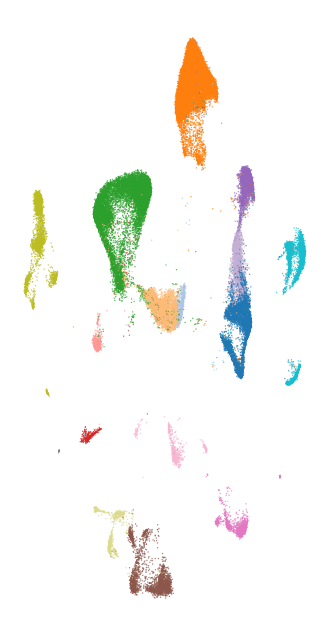

In [36]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Filter out low-count categories
plot_df = plot_df[
    plot_df["v2.subclass.l1"].isin(
        plot_df["v2.subclass.l1"]
        .value_counts()[plot_df["v2.subclass.l1"].value_counts() > 3]
        .index
    )
]

# 2. Shuffle the plotting order to prevent occlusion/stacking of clusters
plot_df = plot_df.sample(frac=1, random_state=42)

# 3. Curated, publication-quality categorical palette for kidney cell types
hue_colors = {
    "PT": "#2ca02c",  # Proximal Tubule (Green)
    "TDL": "#ffbb78",  # Thin Descending Limb (Light Orange)
    "ATL": "#aec7e8",  # Ascending Thin Limb (Light Blue)
    "TAL": "#ff7f0e",  # Thick Ascending Limb (Orange)
    "DCT": "#9467bd",  # Distal Convoluted Tubule (Purple)
    "CNT": "#c5b0d5",  # Connecting Tubule (Light Purple)
    "PC": "#1f77b4",  # Principal Cell (Steel Blue)
    "IC": "#17becf",  # Intercalated Cell (Teal/Cyan)
    "PapE": "#9edae5",  # Papillary Epithelium (Light Cyan)
    "POD": "#d62728",  # Podocyte (Crimson Red)
    "PEC": "#ff9896",  # Parietal Epithelial Cell (Light Red)
    "EC": "#bcbd22",  # Endothelial Cell (Olive Green)
    "VSM/P": "#dbdb8d",  # Vascular Smooth Muscle/Pericyte (Light Olive)
    "FIB": "#8c564b",  # Fibroblast (Brown)
    "NEU": "#7f7f7f",  # Neuron (Grey)
    "Myeloid": "#e377c2",  # Myeloid (Pink)
    "Lymphoid": "#f7b6d2",  # Lymphoid (Light Pink)
}

fig, ax = plt.subplots(figsize=(4, 8))

# 4. Plot with alpha transparency, no edge borders, and rasterized points
sns.scatterplot(
    data=plot_df,
    x="umap_1",
    y="umap_2",
    hue="v2.subclass.l1",
    s=1,
    alpha=0.75,
    edgecolor="none",
    palette=hue_colors,
    rasterized=True,  # Keeps vector text clean while rasterizing dense points
    ax=ax,
)

# Extract coordinates and labels for centroid text placement
embeddings = plot_df[["umap_1", "umap_2"]].values
labels = plot_df["v2.subclass.l1"].values
unique_labels = plot_df["v2.subclass.l1"].unique()

# # 5. Place clean, bold labels at each cluster's median centroid
# for label in unique_labels:
#     if label not in hue_colors:
#         continue
#     mask = labels == label
#     # Using median for both coordinates yields a better geometric center
#     centroid_x = np.median(embeddings[mask, 0])
#     centroid_y = np.median(embeddings[mask, 1])

#     ax.text(
#         centroid_x,
#         centroid_y,
#         label,
#         fontsize=12,  # Adjusted to fit 6x6 figure nicely
#         fontweight="bold",
#         ha="center",
#         va="center",
#         color="black",
#         path_effects=[pe.withStroke(linewidth=3, foreground="white")],
#         zorder=100,
#     )

# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
if legend is not None:
    legend.remove()

plt.savefig(
    r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_plot.png",
    bbox_inches="tight",
    dpi=300,
    transparent=True
)
plt.show()


In [15]:
plot_df['v2.subclass.l1'].unique()

array(['PC', 'TAL', 'DTL', 'FIB', 'IC', 'EC', 'VSM/P', 'Myeloid', 'PT',
       'DCT', 'Lymphoid', 'PEC', 'ATL', 'CNT', 'POD', 'PapE', 'NEU'],
      dtype=object)

## CODEX UMAP Analysis

In [1]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt
Codex_path = r"C:\Users\jvill\/Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_info_1.csv"
codex_df = pd.read_csv(Codex_path)
if 'Unnamed: 0' in codex_df.columns:
    codex_df = codex_df.drop(columns=['Unnamed: 0'])

# Normalize the mean values for each cluster
ab_columns = codex_df.columns[4:-7]
codex_df[ab_columns] = codex_df[ab_columns].apply(lambda x: (x - x.mean()) / x.std(), axis=0)

order =   { 
    "Glomeruli | Podo, CD31" : "Glomeruli | Podo, CD31",
    "PT | LRP2": "PT | LRP2",
    "PT | LRP2, CD90": "PT | LRP2, THY1",
    "PT | LRP2, PROM1,VCAM1": "PT | LRP2, PROM1, VCAM1",
    "TDL | AQP1, Cyto8 (N1)": "TDL | AQP1, Cyto8 (N1)",
    "TDL | AQP1, Cyto8 (N2)": "TDL | AQP1, Cyto8 (N2)",
    "TAL | NaK/UMOD": "TAL | NaK, UMOD",
    "TAL | UMOD (N1)": "TAL | UMOD",
    "DCT | SLC12a3": "DCT | SLC12a3",
    "DN | Cyto8 (N2)": "DN | Cyto8",
    "DN | Cyto8, Bcat": "DN | Cyto8, Bcat",
    "DN | Cyto8, Bcat, Ecad": "DN | Cyto8, Bcat, Ecad",
    "DN | Cyto8, Ecad": "DN | Cyto8, Ecad",
    "Endothelium | CD31,": "Endothelium | CD31",
    "Endothelium | CD31, Podo": "Endothelium | CD31, Podo",
    "Pericytes | CD90+, CD31 (-)": "Pericytes | CD90, CD31(-)",
    "VSMCs | aSMA": "VSMCs | aSMA",
    "Immune - MP | CD45, CD206": "Immune - MP | CD45, CD206",
    "Immune - T | CD3, CD4": "Immune - T | CD3, CD4",
    "Immune - T | CD3, CD8": "Immune - T | CD3, CD8",
    "Interstitial cells | IGFBP7": "Interstitial cells | IGFBP7"
}

codex_ab_columns = codex_df.iloc[:, 4:-7].columns
codex_df['Cluster_Name'] = codex_df['Cluster_Name'].map(order)
heatmap_order = list(order.values())

mean_df = codex_df.groupby('Cluster_Name')[codex_ab_columns].mean().reset_index()
mean_df['Cluster_Name'] = pd.Categorical(mean_df['Cluster_Name'], categories=heatmap_order, ordered=True)
mean_df = mean_df.sort_values('Cluster_Name')

c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


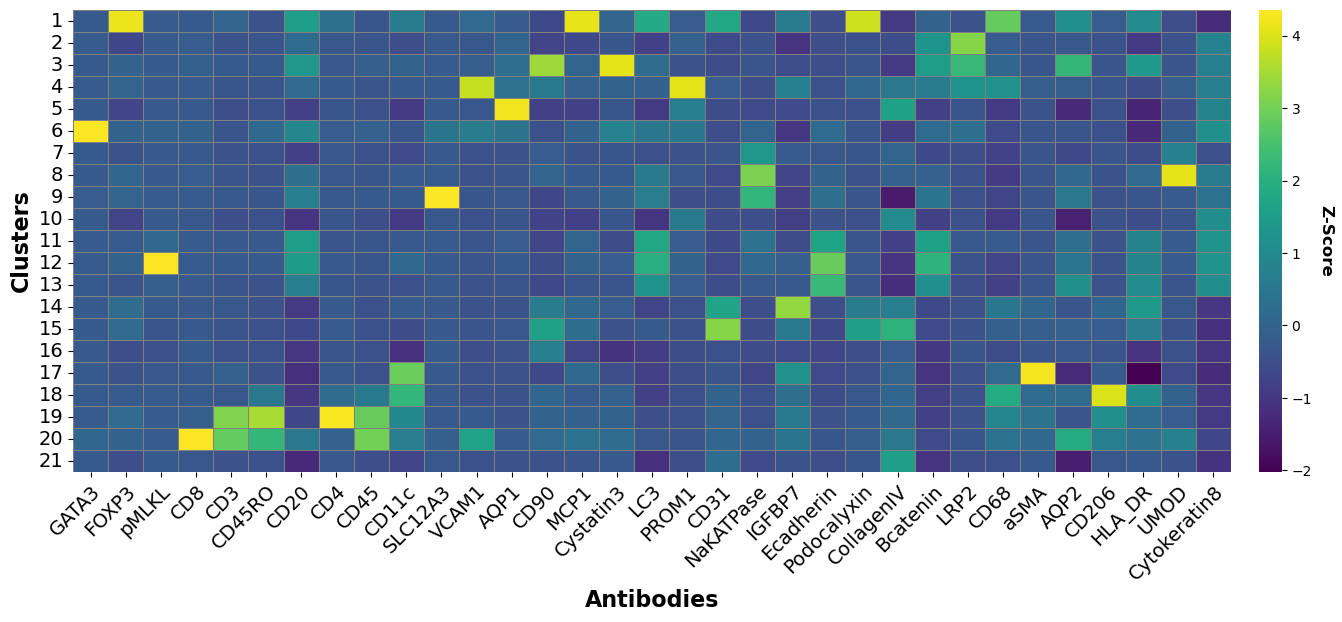

In [6]:
fig, ax = plt.subplots(figsize=(18, 6))

# Z-scale the mean values for better heatmap visualization
heatmap_data = mean_df.iloc[:, 1:].copy()
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

cluster_indeces = [idx for idx, row in enumerate(mean_df['Cluster_Name'].unique(), start=1)]


ax = sns.heatmap(heatmap_data, 
            cmap='viridis', 
            yticklabels=mean_df['Cluster_Name'],
            linewidths=0.5,
            linecolor='gray', cbar=True,
            ax=ax,  cbar_kws={'pad': 0.02})
cbar = ax.collections[0].colorbar
cbar.set_label('Z-Score', size=12, rotation=270, labelpad=15, fontweight='bold')
ax.set_xticklabels(mean_df.columns[1:], rotation=45, ha='right', fontsize=14, rotation_mode='anchor')
ax.set_yticklabels(cluster_indeces, rotation=0, fontsize=14)
# ax.set_title('Normalized Marker Expression by Cluster', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibodies', fontsize=16, fontweight='bold')
ax.set_ylabel('Clusters', fontsize=16, fontweight='bold')

plt.savefig(r"C:\Users\jvill\Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_marker_heatmap.png", bbox_inches='tight', dpi=300, transparent=True)

plt.show()

In [4]:
cluster_indeces

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]